# Tarea 02 - Reconocimiento de Patrones en Imágenes
**Laura Romero**

---

## Instrucciones de uso
1. Colocar la imagen `rice.png` en la misma carpeta que este notebook.
2. Ejecutar las celdas en orden de arriba hacia abajo.
3. Al final se muestra una tabla con las 4 características extraídas para cada grano de arroz:
   - **(1) Color promedio** de cada grano (en escala de grises)
   - **(2) Gradiente promedio** del contorno de cada grano
   - **(3) Contraste** (GLCM) de la región de cada grano
   - **(4) Momentos de Hu** (phi_1) calculados en escala de grises

---

## Paso 1: Importar librerías y cargar la imagen
Primero importamos las librerías que vamos a usar y leemos la imagen en escala de grises.
Usamos `cv2.imread` con el parámetro `0` para leerla directamente en grises.

Tamaño de la imagen: (830, 830)
Valor minimo: 0 Valor maximo: 216


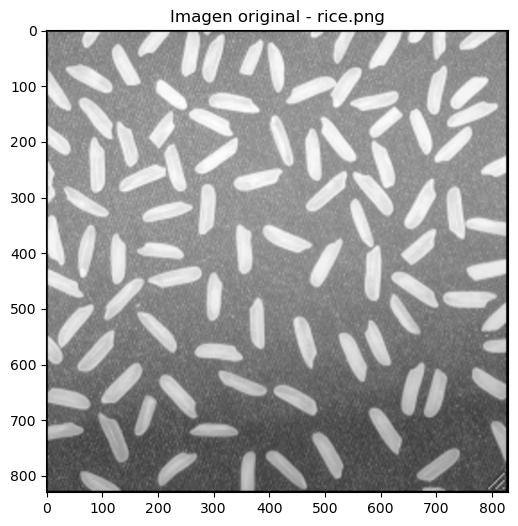

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
from skimage.feature import graycomatrix, graycoprops
import pandas as pd

# leemos la imagen en escala de grises (parametro 0)
img = cv2.imread('rice.png', 0)

print("Tamaño de la imagen:", img.shape)
print("Valor minimo:", img.min(), "Valor maximo:", img.max())

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.title('Imagen original - rice.png')
plt.show()

## Paso 2: Corregir iluminación y binarizar

Al principio se binarizó la imagen directamente con un umbral de 150, pero al revisar los contornos me di cuenta de que en algunos granos no se detectaban porque eran más oscuros que el resto. Esto pasa porque la imagen tiene iluminación no uniforme (unas zonas son más claras que otras).

Para arreglar esto, se estimo el fondo con un blur gaussiano grande y se le resto a la imagen original. Así la iluminación queda más pareja y todos los granos se separan mejor del fondo. Después se binarizo la imagen corregida con cv2.threshold.

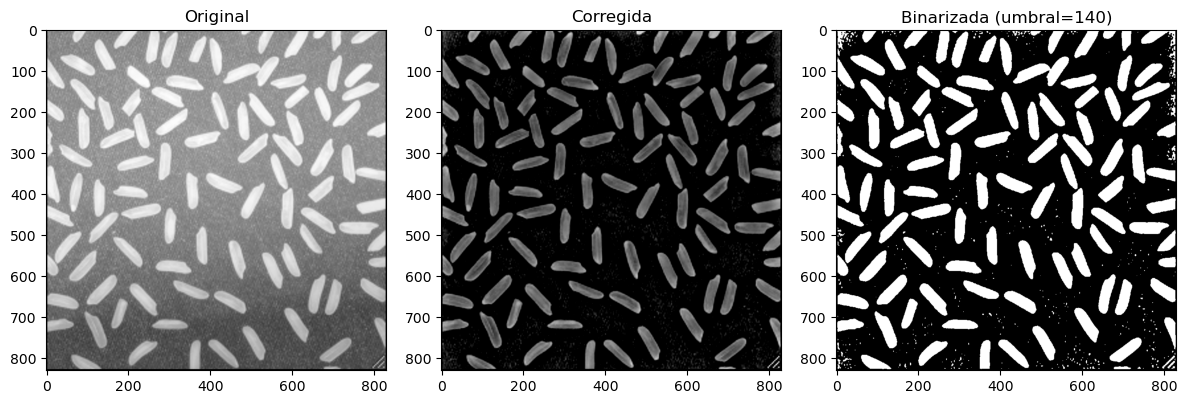

In [38]:
# estimamos el fondo con un blur gaussiano grande
fondo = cv2.GaussianBlur(img, (101, 101), 0)

# restamos el fondo para corregir la iluminacion
corregida = cv2.subtract(img, fondo) + 128

# binarizamos la imagen corregida con umbral 140
th, bw = cv2.threshold(corregida, 140, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.subplot(1,3,2)
plt.imshow(corregida, cmap='gray')
plt.title('Corregida')
plt.subplot(1,3,3)
plt.imshow(bw, cmap='gray')
plt.title('Binarizada (umbral=140)')
plt.tight_layout()
plt.show()

## Paso 3: Encontrar los contornos de cada grano
Usamos `cv2.findContours` para extraer el perímetro de cada grano de arroz.
Filtramos los contornos muy pequeños y también los que tocan el borde de la imagen y son muy chicos (son artefactos de la corrección de iluminación, no granos reales).

Granos de arroz detectados: 100


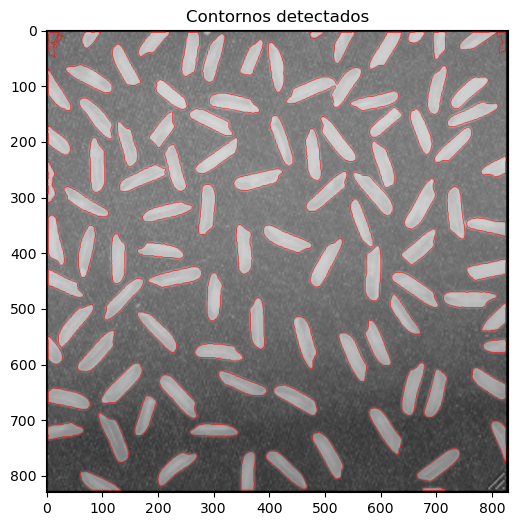

In [40]:
# extraemos los contornos de cada grano
contornos, hc = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

# filtramos contornos muy chicos (ruido)
contornos = [c for c in contornos if cv2.contourArea(c) > 200]

# funcion para saber si un contorno toca el borde de la imagen
def toca_borde(contorno, filas, columnas, margen=3):
    x, y, w, h = cv2.boundingRect(contorno)
    if x <= margen or y <= margen:
        return True
    if (x + w) >= columnas - margen or (y + h) >= filas - margen:
        return True
    return False


print("Granos de arroz detectados:", len(contornos))

# dibujamos los contornos sobre la imagen para verificar
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
cv2.drawContours(img_color, contornos, -1, (255,0,0), 1)

plt.figure(figsize=(6,6))
plt.imshow(img_color)
plt.title('Contornos detectados')
plt.show()

## Paso 4: Definir las funciones para extraer características
Ahora definimos las 4 funciones que calculan cada descriptor.

### 4.1 Color promedio
Es simplemente el promedio de los valores de gris dentro de la región del grano.
En el ramo vimos `np.mean(canal)` para calcular el promedio de un canal.
Acá usamos una máscara para tomar solo los píxeles que pertenecen al grano.

In [28]:
def color_promedio(img_gray, contorno):
    # creamos una mascara negra del tamaño de la imagen
    mascara = np.zeros(img_gray.shape, dtype='uint8')
    # rellenamos la region del grano con blanco
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    # sacamos el promedio solo de los pixeles dentro de la mascara
    promedio = cv2.mean(img_gray, mask=mascara)[0]
    return promedio

### 4.2 Gradiente promedio
Recorremos los píxeles del contorno y calculamos el gradiente en cada punto.
En clases se definió la función `gradiente`:
- Lx = -0.5 * L[i-1,j] + 0.5 * L[i+1,j]
- Ly = -0.5 * L[i,j-1] + 0.5 * L[i,j+1]
- magnitud = sqrt(Lx² + Ly²)

Y al final se promedia la magnitud sobre todos los puntos del contorno.

In [ ]:
def gradiente_promedio(img_gray, contorno):
    # misma logica que la funcion gradiente() 
    # recorremos cada punto del contorno y calculamos Lx y Ly
    pos = np.vstack(contorno)
    filas, columnas = img_gray.shape
    mag = 0
    N = 0
    
    for punto in pos:
        j, i = punto[0], punto[1]
        
        # nos aseguramos de no salirnos de los bordes de la imagen
        if i > 0 and i < filas-1 and j > 0 and j < columnas-1:
            # derivada en x: diferencia centrada
            lx = -0.5 * float(img_gray[i-1, j]) + 0.5 * float(img_gray[i+1, j])
            # derivada en y: diferencia centrada
            ly = -0.5 * float(img_gray[i, j-1]) + 0.5 * float(img_gray[i, j+1])
            # magnitud del gradiente
            mag += sqrt(lx**2 + ly**2)
            N += 1
    
    if N == 0:
        return 0
    
    promedio = mag / N
    return promedio

### 4.3 Contraste (GLCM)
Usamos la matriz de co-ocurrencia (GLCM).
Pasos:
1. Extraemos la sub-imagen del grano.
2. Reducimos los niveles de gris con `MinMaxScaler` .
3. Calculamos la GLCM con `graycomatrix`.
4. Extraemos el contraste con `graycoprops`.

In [34]:
def contraste_glcm(img_gray, contorno):
    # sacamos el bounding box del grano
    x, y, w, h = cv2.boundingRect(contorno)
    
    # recortamos la sub-imagen del grano
    roi = img_gray[y:y+h, x:x+w]
    
    # creamos una mascara solo para la region del grano dentro del recorte
    mascara_roi = np.zeros((h, w), dtype='uint8')
    contorno_desplazado = contorno - np.array([x, y])
    cv2.drawContours(mascara_roi, [contorno_desplazado], -1, 255, -1)
    
    # aplicamos la mascara: los pixeles fuera del grano quedan en 0
    roi_masked = cv2.bitwise_and(roi, roi, mask=mascara_roi)
    
    # reducimos niveles de gris 
    # usamos MinMaxScaler para escalar a rango (0, 15)
    from sklearn import preprocessing
    columna = roi_masked.reshape(-1, 1)
    new_scale = (0, 15)
    new_roi = preprocessing.MinMaxScaler(new_scale).fit_transform(columna.astype(float)).astype(int)
    new_roi = new_roi.reshape(roi_masked.shape)
    
    # calculamos la GLCM 
    niveles = np.max(new_roi) + 1
    if niveles < 2:
        return 0
    
    P = graycomatrix(new_roi.astype('uint8'), distances=[1], angles=[0], levels=niveles, symmetric=False, normed=False)
    
    # extraemos el contraste (como en clase 10, celda 40)
    contraste = graycoprops(P, 'contrast').squeeze()
    return float(contraste)

### 4.4 Momentos de Hu (phi_1) en escala de grises
Los momentos de Hu se calcularon con las funciones:
- `mrs(imagen, r, s)` = momento crudo de orden (r,s)
- `mu_rs(imagen, r, s)` = momento central (trasladado al centro de masa)
- `eta_rs(imagen, r, s)` = momento normalizado (invariante a escala)
- phi_1 = eta(2,0) + eta(0,2) --> primer momento de Hu

El enunciado dice "en escala de grises", así que en vez de usar la imagen binaria (0 y 1),
usamos los valores reales de gris de cada grano como pesos.

In [ ]:
def mrs(pixeles_i, pixeles_j, pesos, r, s):
    # momento crudo m(r,s) = sum( I^r * J^s * peso )
  
    # aca agregamos los pesos (valores de gris) para que sea en escala de grises
    return np.sum((pixeles_i**r) * (pixeles_j**s) * pesos)

def mu_rs(pixeles_i, pixeles_j, pesos, r, s):
    # momento central mu(r,s) 
    # primero calculamos el centro de masa
    m00 = mrs(pixeles_i, pixeles_j, pesos, 0, 0)
    cx = mrs(pixeles_i, pixeles_j, pesos, 1, 0) / m00
    cy = mrs(pixeles_i, pixeles_j, pesos, 0, 1) / m00
    # momento central: desplazamos al centro de masa
    return np.sum(((pixeles_i - cx)**r) * ((pixeles_j - cy)**s) * pesos)

def eta_rs(pixeles_i, pixeles_j, pesos, r, s):
    # momento normalizado eta(r,s) 
    # t = (r+s)/2 + 1
    t = (r + s) / 2 + 1
    mu00 = mu_rs(pixeles_i, pixeles_j, pesos, 0, 0)
    if mu00 == 0:
        return 0
    return mu_rs(pixeles_i, pixeles_j, pesos, r, s) / (mu00 ** t)

def momento_hu_phi1(img_gray, contorno):
    # creamos mascara para obtener los pixeles del grano
    mascara = np.zeros(img_gray.shape, dtype='uint8')
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    
    # obtenemos las coordenadas (i, j) de los pixeles del grano
    I, J = np.where(mascara == 255)
    
    # los pesos son los valores de gris de esos pixeles
    pesos = img_gray[I, J].astype(float)
    
    # phi_1 = eta(2,0) + eta(0,2) 
    phi_1 = eta_rs(I, J, pesos, 2, 0) + eta_rs(I, J, pesos, 0, 2)
    return phi_1

## Paso 5: Extraer las 4 características para cada grano
Ahora recorremos cada grano de arroz detectado y calculamos las 4 características.
Guardamos todo en una lista para después armar la tabla.

In [35]:
# lista donde guardamos los resultados de cada grano
resultados = []

for idx, contorno in enumerate(contornos):
    # (1) Color promedio
    color = color_promedio(img, contorno)
    
    # (2) Gradiente promedio (usa la imagen original en grises + contorno de la binarizada)
    grad = gradiente_promedio(img, contorno)
    
    # (3) Contraste GLCM
    contr = contraste_glcm(img, contorno)
    
    # (4) Momentos de Hu phi_1 en escala de grises
    hu = momento_hu_phi1(img, contorno)
    
    resultados.append([idx+1, color, grad, contr, hu])

print("Caracteristicas extraidas para", len(resultados), "granos")

Caracteristicas extraidas para 100 granos


## Paso 6: Mostrar la tabla de resultados
Armamos un DataFrame de pandas para que se vea ordenado.

In [37]:
# armamos la tabla con pandas
columnas = ['Grano', 'Color Promedio', 'Gradiente Promedio', 'Contraste (GLCM)', 'Hu phi_1']
df = pd.DataFrame(resultados, columns=columnas)
df = df.set_index('Grano')

# mostramos la tabla completa
print("TABLA DE CARACTERISTICAS POR GRANO DE ARROZ")
print("")
print(df.to_string())
print("")
print("Total de granos:", len(df))

TABLA DE CARACTERISTICAS POR GRANO DE ARROZ

       Color Promedio  Gradiente Promedio  Contraste (GLCM)  Hu phi_1
Grano                                                                
1          133.057143           44.999898          3.118467  0.003729
2          144.771549           22.163778          2.720939  0.001823
3          149.620582           18.256278          2.940429  0.001829
4          151.344025           18.552451          6.054648  0.001707
5          141.273422           18.534830          2.764591  0.002376
6          139.540960           18.364696          2.806926  0.002011
7          148.339890           19.105498          3.911444  0.001960
8          146.952147           15.667465          2.027778  0.002119
9          148.601695           24.252473          2.394043  0.001610
10         144.914582           29.116569          7.037987  0.002209
11         138.727039           17.645206          4.197942  0.002108
12         151.295718           19.472609    